# Is LIME as faithful as SHAP?

Notebooks 02 and 03 measured and illustrated SHAP. The measurement machinery,
however, never cared where the attributions came from: it ranks spans by
attributed importance, cuts them through the word masker, and watches the
output. Any method that produces one number per word, aligned with the same
word split, runs through the identical pipeline. That is the comparison
protocol of this project, and LIME is the first alternative through it.

LIME earns the comparison by being SHAP's methodological opposite. It drops
random subsets of words, replaces them with the same `...` marker the masker
uses, and fits a weighted ridge regression from the dropout patterns to the
model outputs. The surrogate's weights are the attributions. There is no
additivity guarantee and no game theory, the quality rests entirely on whether
a local linear fit captures the model's behavior around the review.

Three choices keep the comparison fair:

- Both methods are evaluated with the same masker and the same cuts, so
  neither is measured against a perturbation scheme it never saw.
- The budgets are comparable. SHAP's partition explainer spent at most 500
  model evaluations per review in notebook 02, LIME gets 1000 samples here,
  which if anything is generous to LIME.
- Each method is compared against its own shuffled control, because chunk
  combining consumes the attribution values, not only their ranks, so the
  control must preserve each method's own value distribution.

## Configuration

In [1]:
from pathlib import Path

from textfaith.faithfulness import ABSOLUTE_SUM, MAX_ABSOLUTE, SUM_ABSOLUTE

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHECKPOINT_DIRECTORY = PROJECT_ROOT / "artifacts" / "sample_2000"

OBSERVATION_COUNT = 100
PERCENTILES = [10, 20, 30, 40, 50]
CHUNK_SIZES = [1, 4, 8]
COMBINATIONS = [ABSOLUTE_SUM, SUM_ABSOLUTE, MAX_ABSOLUTE]
RANDOM_SEED = 42
LIME_SAMPLE_COUNT = 1000

SHAP_ATTRIBUTIONS_PATH = CHECKPOINT_DIRECTORY / f"word_attributions_{OBSERVATION_COUNT}.joblib"
LIME_ATTRIBUTIONS_PATH = CHECKPOINT_DIRECTORY / f"lime_word_attributions_{OBSERVATION_COUNT}.joblib"

print(f"Checkpoint: {CHECKPOINT_DIRECTORY}")
print(f"Percentiles: {PERCENTILES}")
print(f"Chunk sizes: {CHUNK_SIZES}")
print(f"Combinations: {COMBINATIONS}")
print(f"LIME samples per review: {LIME_SAMPLE_COUNT}")

/home/user/projects/shapley/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Checkpoint: /home/user/projects/shapley/artifacts/sample_2000
Percentiles: [10, 20, 30, 40, 50]
Chunk sizes: [1, 4, 8]
Combinations: ['absolute_sum', 'sum_absolute', 'max_absolute']
LIME samples per review: 1000


## Load the classifier, the sample, and the SHAP attributions

The sample must reproduce notebook 02's exactly, same seed, same
stratification, because both attribution caches are positional. The SHAP cache
is required, not recomputed, run notebook 02 first if it is missing. The
alignment assertion catches any drift between the caches and the sample.

In [2]:
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split

from textfaith.checkpoint import load_predictor
from textfaith.faithfulness import build_word_masker

predict_probabilities, tokenizer = load_predictor(CHECKPOINT_DIRECTORY)

test_reviews = pd.read_parquet(CHECKPOINT_DIRECTORY / "test.parquet")
sampled_reviews, _ = train_test_split(
    test_reviews,
    train_size=OBSERVATION_COUNT,
    random_state=RANDOM_SEED,
    stratify=test_reviews["label"],
)
texts = sampled_reviews["text"].tolist()

masker = build_word_masker()

assert SHAP_ATTRIBUTIONS_PATH.exists(), "No SHAP cache, run notebooks/02_faithfulness.ipynb first"
shap_attributions = joblib.load(SHAP_ATTRIBUTIONS_PATH)

for text, attribution in zip(texts, shap_attributions):
    assert len(attribution) == len(masker.data_transform(text)[0]), (
        "Cached SHAP attributions do not align with this sample, rebuild the cache"
    )

print(f"Loaded predictor and {len(shap_attributions)} cached SHAP attribution arrays")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19733.47it/s]

Loaded predictor and 100 cached SHAP attribution arrays


## Compute the LIME attributions

`compute_lime_word_attributions` mirrors the SHAP convention: signed weights
for the predicted class, one per word position, aligned with the masker's
word split. Like the SHAP run this is the expensive step, roughly 50 minutes
for 100 reviews at 1000 samples each on 8 CPU cores, and it is cached the
same way.

In [3]:
from textfaith.faithfulness import compute_lime_word_attributions

if LIME_ATTRIBUTIONS_PATH.exists():
    lime_attributions = joblib.load(LIME_ATTRIBUTIONS_PATH)
    print("Loaded cached LIME attributions")
else:
    print("Explaining with LIME, expect roughly 50 minutes")
    lime_attributions = compute_lime_word_attributions(
        predict_probabilities,
        texts,
        masker,
        random_seed=RANDOM_SEED,
        sample_count=LIME_SAMPLE_COUNT,
    )
    joblib.dump(lime_attributions, LIME_ATTRIBUTIONS_PATH)

for shap_attribution, lime_attribution in zip(shap_attributions, lime_attributions):
    assert len(shap_attribution) == len(lime_attribution), (
        "LIME attributions do not align with the SHAP attributions"
    )

import numpy as np

total_word_count = sum(len(attribution) for attribution in lime_attributions)
negative_share = sum(
    (attribution < 0).sum() for attribution in lime_attributions
) / total_word_count
print(f"LIME attributions for {len(lime_attributions)} reviews, {total_word_count} words")
print(f"Share of words pushing against the predicted class: {negative_share:.1%}")

Explaining with LIME, expect roughly 50 minutes


LIME attributions for 100 reviews, 19166 words
Share of words pushing against the predicted class: 45.0%


## How similar are the two rankings?

If LIME and SHAP produced near identical rankings, the faithfulness comparison
would be a foregone conclusion. Rank correlation on the signed values and
overlap among each review's ten most important words show how much room the
two methods actually have to differ.

In [4]:
from scipy.stats import spearmanr

TOP_WORD_COUNT = 10

rank_correlations = np.array([
    spearmanr(lime_attribution, shap_attribution).statistic
    for lime_attribution, shap_attribution in zip(lime_attributions, shap_attributions)
])
top_word_overlaps = np.array([
    len(
        set(np.argsort(-np.abs(lime_attribution))[:TOP_WORD_COUNT])
        & set(np.argsort(-np.abs(shap_attribution))[:TOP_WORD_COUNT])
    ) / TOP_WORD_COUNT
    for lime_attribution, shap_attribution in zip(lime_attributions, shap_attributions)
])

quartiles = np.percentile(rank_correlations, [25, 50, 75])
print(
    f"Spearman correlation between LIME and SHAP per review: "
    f"median {quartiles[1]:.2f}, interquartile range {quartiles[0]:.2f} to {quartiles[2]:.2f}"
)
print(
    f"Overlap among the top {TOP_WORD_COUNT} words by magnitude: "
    f"mean {top_word_overlaps.mean():.1%}"
)

Spearman correlation between LIME and SHAP per review: median 0.29, interquartile range 0.20 to 0.37
Overlap among the top 10 words by magnitude: mean 30.6%


## Correctness check before trusting any number

Cutting at percentile 0 keeps every chunk, so the measured shift must be zero
up to float32 batching noise. Notebook 02 proved this for the machinery, this
run proves the LIME arrays feed it correctly end to end.

In [5]:
from textfaith.faithfulness import measure_sufficiency

no_cut_shift = measure_sufficiency(
    predict_probabilities, texts, [0], masker, lime_attributions
)
assert np.allclose(no_cut_shift, 0, atol=1e-6), "Cutting nothing moved the output"
print(f"Cutting nothing moves the output by at most {np.abs(no_cut_shift).max():.2e}, as required")

Cutting nothing moves the output by at most 0.00e+00, as required


## Sweep the grid for both methods

The same grid as notebook 02, once per method, each with its own shuffled
control: chunk size, combination, direction, four attribution sources. This
is 72 measurements of 600 predictions each, roughly 20 minutes.

In [6]:
from textfaith.faithfulness import measure_comprehensiveness, shuffle_attributions

attribution_sources = {
    "shap": shap_attributions,
    "lime": lime_attributions,
    "shap_random": shuffle_attributions(shap_attributions, RANDOM_SEED),
    "lime_random": shuffle_attributions(lime_attributions, RANDOM_SEED),
}

records = []
for chunk_size in CHUNK_SIZES:
    for combination in COMBINATIONS:
        for source, attributions in attribution_sources.items():
            for direction, measure in [
                ("sufficiency", measure_sufficiency),
                ("comprehensiveness", measure_comprehensiveness),
            ]:
                records.append(
                    {
                        "chunk_size": chunk_size,
                        "combination": combination,
                        "source": source,
                        "direction": direction,
                        "values": measure(
                            predict_probabilities, texts, PERCENTILES, masker,
                            attributions, chunk_size=chunk_size, combination=combination,
                        ),
                    }
                )

print(f"Measured {len(records)} grid cells, each of shape {records[0]['values'].shape}")

Measured 72 grid cells, each of shape (100, 5)


## Results

Every arm runs on the same 100 reviews, so the honest statistic is paired.
The advantage columns are the mean paired difference divided by its standard
error, averaged over percentiles, positive when SHAP is better. Sufficiency is
better when lower, comprehensiveness when higher, and the advantage columns
already point the same way for both, above roughly 2 the gap exceeds sampling
noise. The ratio columns compare each method against its own shuffled control,
above 1 means the method beats a random ranking at all.

In [7]:
from textfaith.faithfulness import paired_advantage


def lookup(chunk_size, combination, source, direction):
    for record in records:
        if (record["chunk_size"], record["combination"], record["source"], record["direction"]) == (
            chunk_size, combination, source, direction
        ):
            return record["values"]
    raise KeyError((chunk_size, combination, source, direction))


rows = []
for chunk_size in CHUNK_SIZES:
    for combination in COMBINATIONS:
        shap_sufficiency = lookup(chunk_size, combination, "shap", "sufficiency")
        lime_sufficiency = lookup(chunk_size, combination, "lime", "sufficiency")
        shap_comprehensiveness = lookup(chunk_size, combination, "shap", "comprehensiveness")
        lime_comprehensiveness = lookup(chunk_size, combination, "lime", "comprehensiveness")
        rows.append(
            {
                "chunk_size": chunk_size,
                "combination": combination,
                "sufficiency_shap": shap_sufficiency.mean(),
                "sufficiency_lime": lime_sufficiency.mean(),
                "sufficiency_shap_advantage": paired_advantage(
                    lime_sufficiency, shap_sufficiency
                ),
                "sufficiency_ratio_shap": lookup(
                    chunk_size, combination, "shap_random", "sufficiency"
                ).mean() / shap_sufficiency.mean(),
                "sufficiency_ratio_lime": lookup(
                    chunk_size, combination, "lime_random", "sufficiency"
                ).mean() / lime_sufficiency.mean(),
                "comprehensiveness_shap": shap_comprehensiveness.mean(),
                "comprehensiveness_lime": lime_comprehensiveness.mean(),
                "comprehensiveness_shap_advantage": paired_advantage(
                    shap_comprehensiveness, lime_comprehensiveness
                ),
                "comprehensiveness_ratio_shap": shap_comprehensiveness.mean() / lookup(
                    chunk_size, combination, "shap_random", "comprehensiveness"
                ).mean(),
                "comprehensiveness_ratio_lime": lime_comprehensiveness.mean() / lookup(
                    chunk_size, combination, "lime_random", "comprehensiveness"
                ).mean(),
            }
        )

grid = pd.DataFrame(rows).set_index(["chunk_size", "combination"])
print("Mean absolute probability shift, averaged over percentiles")
grid

Mean absolute probability shift, averaged over percentiles


sufficiency_shap  sufficiency_lime  \
chunk_size combination                                        
1          absolute_sum          0.038605          0.048954   
           sum_absolute          0.038605          0.048954   
           max_absolute          0.038605          0.048954   
4          absolute_sum          0.036938          0.036757   
           sum_absolute          0.035891          0.035238   
           max_absolute          0.036120          0.036108   
8          absolute_sum          0.039622          0.039064   
           sum_absolute          0.036874          0.039382   
           max_absolute          0.037545          0.042530   

                         sufficiency_shap_advantage  sufficiency_ratio_shap  \
chunk_size combination                                                        
1          absolute_sum                    2.142389                1.979182   
           sum_absolute                    2.142389                1.979182   
           max_absolute                    2.142389                1.979182   
4          absolute_sum                   -0.068288                1.555675   
           sum_absolute                   -0.171159                1.610604   
           max_absolute                   -0.106815                1.553713   
8          absolute_sum                   -0.006806                1.351314   
           sum_absolute                    0.593503                1.353449   
           max_absolute                    1.194792                1.360959   

                         sufficiency_ratio_lime  comprehensiveness_shap  \
chunk_size combination                                                    
1          absolute_sum                1.611456                0.108781   
           sum_absolute                1.611456                0.108781   
           max_absolute                1.611456                0.108781   
4          absolute_sum                1.514282                0.100716   
           sum_absolute                1.646181                0.098196   
           max_absolute                1.657146                0.097654   
8          absolute_sum                1.204898                0.091347   
           sum_absolute                1.242147                0.088808   
           max_absolute                1.134210                0.087938   

                         comprehensiveness_lime  \
chunk_size combination                            
1          absolute_sum                0.128411   
           sum_absolute                0.128411   
           max_absolute                0.128411   
4          absolute_sum                0.095512   
           sum_absolute                0.092565   
           max_absolute                0.088969   
8          absolute_sum                0.089728   
           sum_absolute                0.079885   
           max_absolute                0.082863   

                         comprehensiveness_shap_advantage  \
chunk_size combination                                      
1          absolute_sum                         -2.598966   
           sum_absolute                         -2.598966   
           max_absolute                         -2.598966   
4          absolute_sum                          0.699578   
           sum_absolute                          0.829013   
           max_absolute                          1.386861   
8          absolute_sum                          0.299682   
           sum_absolute                          1.058712   
           max_absolute                          0.697499   

                         comprehensiveness_ratio_shap  \
chunk_size combination                                  
1          absolute_sum                      1.318004   
           sum_absolute                      1.318004   
           max_absolute                      1.318004   
4          absolute_sum                      1.771702   
           sum_absolute                      1.761468   
  

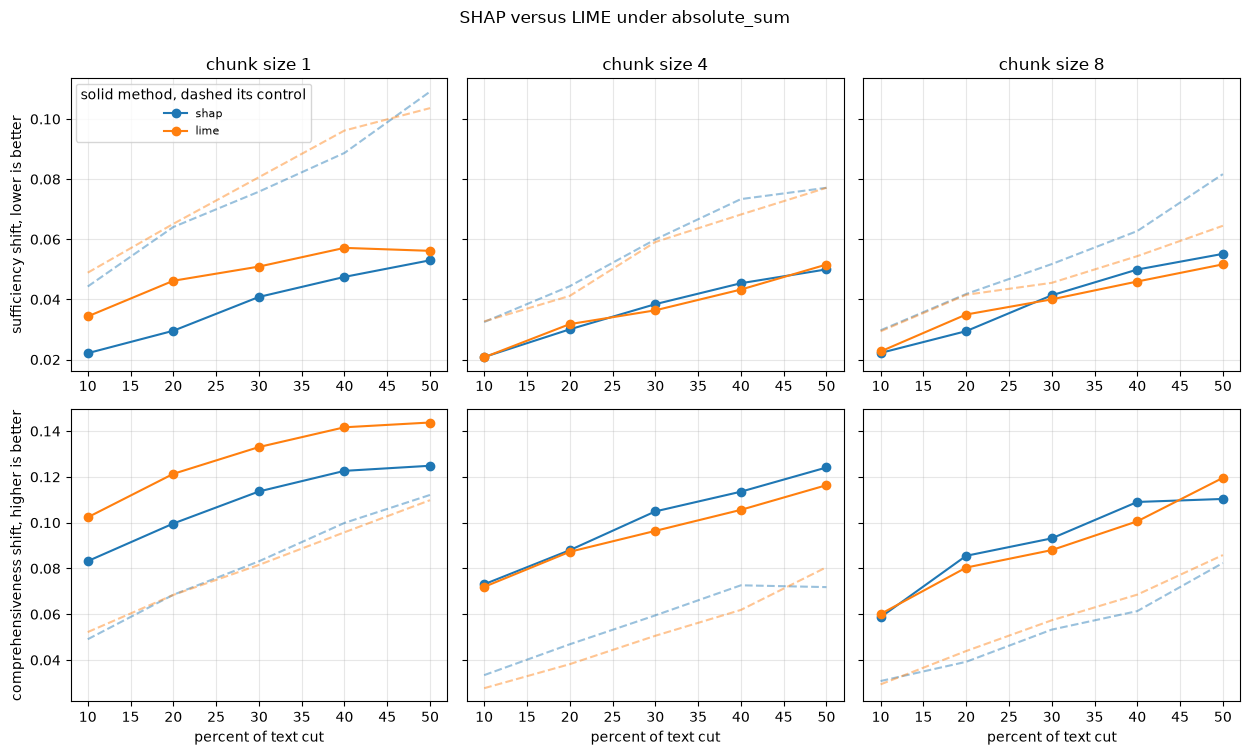

In [8]:
import matplotlib.pyplot as plt

method_colors = {"shap": "C0", "lime": "C1"}

figure, axes = plt.subplots(
    2, len(CHUNK_SIZES), figsize=(4.2 * len(CHUNK_SIZES), 7.5), sharey="row"
)
for row_index, direction in enumerate(["sufficiency", "comprehensiveness"]):
    for axis, chunk_size in zip(axes[row_index], CHUNK_SIZES):
        for method in ["shap", "lime"]:
            axis.plot(
                PERCENTILES,
                lookup(chunk_size, ABSOLUTE_SUM, method, direction).mean(axis=0),
                "-o", color=method_colors[method], label=method,
            )
            axis.plot(
                PERCENTILES,
                lookup(chunk_size, ABSOLUTE_SUM, f"{method}_random", direction).mean(axis=0),
                "--", color=method_colors[method], alpha=0.45,
            )
        if row_index == 0:
            axis.set_title(f"chunk size {chunk_size}")
        else:
            axis.set_xlabel("percent of text cut")
        axis.grid(alpha=0.3)

axes[0][0].set_ylabel("sufficiency shift, lower is better")
axes[1][0].set_ylabel("comprehensiveness shift, higher is better")
axes[0][0].legend(title="solid method, dashed its control", fontsize=8)
figure.suptitle(f"SHAP versus LIME under {ABSOLUTE_SUM}", y=1.0)
figure.tight_layout()
plt.show()

## Reading of the result

The two methods disagree far more than their reputations suggest, a median
rank correlation of 0.29 and less than a third of each review's top ten words
shared, yet both beat their shuffled controls in every one of the 18 grid
cells. Substantially different rankings can evidently both be faithful, which
is the most useful finding here: faithfulness does not pin down a unique
explanation.

The head to head splits cleanly along the two directions at word level. SHAP
is better at sufficiency, the text it dismisses really is ignorable, while
LIME is better at comprehensiveness, the words it crowns move the model more
when cut, and both gaps sit just past the noise threshold of 2. The split is
consistent with how each method estimates: LIME's dropout regression rewards
words whose individual removal swings the surrogate, concentrating quality at
the top of its ranking, while SHAP's partition estimates spread credit
additively and are more reliable about the long unimportant tail. At chunk
sizes 4 and 8 every advantage collapses into sampling noise, aggregating over
spans washes the methods' differences out.

One caveat keeps the verdict honest: LIME ran with roughly twice SHAP's
evaluation budget per review, so the chunk level parity is, if anything,
slightly flattering to LIME.

In [9]:
print(f"Head to head under {ABSOLUTE_SUM}, positive advantage favors SHAP")
print()
for chunk_size in CHUNK_SIZES:
    row = grid.loc[(chunk_size, ABSOLUTE_SUM)]
    sufficiency_winner = "SHAP" if row["sufficiency_shap_advantage"] > 0 else "LIME"
    comprehensiveness_winner = (
        "SHAP" if row["comprehensiveness_shap_advantage"] > 0 else "LIME"
    )
    print(
        f"chunk {chunk_size}: sufficiency favors {sufficiency_winner} "
        f"(advantage {row['sufficiency_shap_advantage']:+.1f}), "
        f"comprehensiveness favors {comprehensiveness_winner} "
        f"(advantage {row['comprehensiveness_shap_advantage']:+.1f})"
    )

print()
beats_control = (grid["sufficiency_ratio_lime"] > 1).all() and (
    grid["comprehensiveness_ratio_lime"] > 1
).all()
print(
    "LIME beats its shuffled control in every grid cell."
    if beats_control
    else "LIME fails to beat its shuffled control in at least one grid cell."
)

Head to head under absolute_sum, positive advantage favors SHAP

chunk 1: sufficiency favors SHAP (advantage +2.1), comprehensiveness favors LIME (advantage -2.6)
chunk 4: sufficiency favors LIME (advantage -0.1), comprehensiveness favors SHAP (advantage +0.7)
chunk 8: sufficiency favors LIME (advantage -0.0), comprehensiveness favors SHAP (advantage +0.3)

LIME beats its shuffled control in every grid cell.
